In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans



X_train = np.array([
    [22, 1, 0, 8.5],

    [25, 1, 0, 9.0],
    [19, 2, 0, 7.5],
    [21, 1, 0, 8.0],
    [24, 2, 0, 8.2],
    [20, 1, 0, 9.0],
    [23, 1, 0, 7.8],
    [26, 2, 0, 8.5],
    [18, 1, 0, 7.0],
    [22, 2, 0, 8.8],
    [35, 2, 0, 5.2],
    [42, 2, 0, 4.8],
    [38, 2, 0, 5.5],
    [45, 2, 0, 4.2],
    [40, 2, 0, 5.0],
    [37, 2, 0, 5.8],
    [44, 2, 0, 4.5],
    [36, 2, 0, 6.0],
    [41, 2, 0, 5.2],
    [39, 2, 0, 4.9],
    [34, 4, 2, 3.5],
    [38, 5, 3, 3.0],
    [42, 4, 2, 2.8],
    [35, 6, 4, 2.5],
    [40, 4, 2, 3.2],
    [37, 5, 3, 2.9],
    [43, 4, 2, 3.1],
    [36, 6, 4, 2.7],
    [41, 5, 3, 3.4],
    [39, 4, 2, 3.0],
])
print(X_train)

[[22.   1.   0.   8.5]
 [25.   1.   0.   9. ]
 [19.   2.   0.   7.5]
 [21.   1.   0.   8. ]
 [24.   2.   0.   8.2]
 [20.   1.   0.   9. ]
 [23.   1.   0.   7.8]
 [26.   2.   0.   8.5]
 [18.   1.   0.   7. ]
 [22.   2.   0.   8.8]
 [35.   2.   0.   5.2]
 [42.   2.   0.   4.8]
 [38.   2.   0.   5.5]
 [45.   2.   0.   4.2]
 [40.   2.   0.   5. ]
 [37.   2.   0.   5.8]
 [44.   2.   0.   4.5]
 [36.   2.   0.   6. ]
 [41.   2.   0.   5.2]
 [39.   2.   0.   4.9]
 [34.   4.   2.   3.5]
 [38.   5.   3.   3. ]
 [42.   4.   2.   2.8]
 [35.   6.   4.   2.5]
 [40.   4.   2.   3.2]
 [37.   5.   3.   2.9]
 [43.   4.   2.   3.1]
 [36.   6.   4.   2.7]
 [41.   5.   3.   3.4]
 [39.   4.   2.   3. ]]


In [2]:
#training clustering modele:
model=KMeans(n_clusters=3)
model.fit(X_train)

C:\D disk\9raya\AI\instal\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


,n_clusters,3
,init,'k-means++'
,n_init,'auto'
,max_iter,300
,tol,0.0001
,verbose,0
,random_state,None
,copy_x,True
,algorithm,'lloyd'


In [3]:
#We will divide the data into 3 clusters groups
X_train_predict=model.labels_
print("\nall data prediction")
print(X_train_predict)


all data prediction
[1 1 1 1 1 1 1 1 1 1 2 0 0 0 0 2 0 2 0 0 2 2 0 2 0 2 0 2 0 0]


In [4]:
#we will make each group it's own average for each parameter
#so we can understand what our medel depend on for clustering
centres=model.cluster_centers_
centres_df = pd.DataFrame(centres, columns=['Age', 'Taille_Groupe', 'Nb_Enfants', 'Score_Physique'])
print(centres_df.round(2))


     Age  Taille_Groupe  Nb_Enfants  Score_Physique
0  41.17           2.92        0.92            4.13
1  22.00           1.40       -0.00            8.23
2  36.00           4.00        2.00            3.95


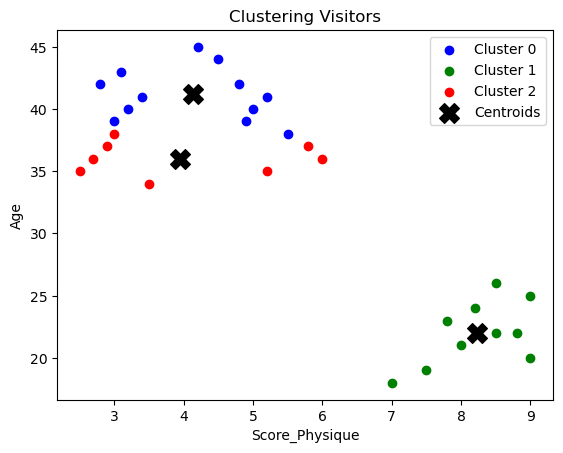

In [5]:


colors = ['blue', 'green', 'red']
labels_pred = model.labels_

# Plot data points
for cluster in range(3):
    points = X_train[labels_pred == cluster]
    plt.scatter(points[:, 3], points[:, 0], 
                c=colors[cluster], label=f'Cluster {cluster}')

# Plot centroids
plt.scatter(centres[:, 3], centres[:, 0], 
            c='black', marker='X', s=200, label='Centroids')

plt.xlabel('Score_Physique')
plt.ylabel('Age')
plt.title('Clustering Visitors')
plt.legend()
plt.show()

In [6]:
#centre 0: with average age= 36, highest centre that come with group and kids
    #, low physical Activite=4
#centre 1: with average age=22(youngest), most of them come alone with no kids
    #, highest physical Activit= 8
#centre 2: with average age= 41(oldest), most of the time come with group and maybe some kids
    #, low physical Activite=4
